# 01 · Number of clusters

Three reference configurations are fitted for k = 2, 3, 4 and 5:

- **C1**: clinical variables only (Robust G-Gower, robust Mahalanobis in the clinical block)
- **M1**: images and clinical variables (RelMS; Euclidean image blocks, robust Mahalanobis clinical block)
- **I1**: images only (RelMS; Euclidean image blocks)

For each k I look at the cluster profiles, the medoid patients and the Pairwise Separability Index (PSI), and
choose k by how interpretable the clusters are, using the PSI as support. The other configurations are then fitted directly at the chosen k, so that
each one differs from its reference in only one thing.

| | Used to build the clusters | Used to interpret them |
|---|---|---|
| C1 | Age, MMSE, eTIV, nWBV, Educ, SES | Age, MMSE, nWBV, eTIV, Educ, SES, CDR, sex |
| M1 | 5 × 110 image PCs + the C1 variables | same |
| I1 | 5 × 110 image PCs | same |

ASF is not used (r = −0.99 with eTIV). Sex is not used to build the clusters, and CDR only enters C2 and M3.

In [1]:
%run -i ../src/setup.ipynb

OUT = cfg.RESULTS_DIR / "01_choose_k"
OUT.mkdir(parents=True, exist_ok=True)
print("results are saved in:", OUT.relative_to(ROOT))

results are saved in: results\01_choose_k


## 1. Analysis sample

216 patients with complete clinical data and all five image types, without imputation.

In [2]:
df = load_analysis_data()
print(f"patients: {len(df)}")
print("sex:", df["M/F"].value_counts().to_dict())
print("CDR:", df["CDR"].value_counts().sort_index().to_dict())
df[["Age", "MMSE", "eTIV", "nWBV", "Educ", "SES", "CDR"]].describe().round(2)

patients: 216
sex: {'F': 145, 'M': 71}
CDR: {0.0: 133, 0.5: 57, 1.0: 24, 2.0: 2}


,Age,MMSE,eTIV,nWBV,Educ,SES,CDR
count,216.00,216.00,216.00,216.00,216.00,216.00,216.00
mean,72.44,27.32,1458.64,0.75,3.23,2.49,0.26
std,12.31,3.44,160.52,0.05,1.33,1.12,0.38
min,33.00,15.00,1123.00,0.64,1.00,1.00,0.00
25%,66.00,26.00,1346.00,0.72,2.00,2.00,0.00
50%,73.00,29.00,1445.50,0.75,3.00,2.00,0.00
75%,81.00,30.00,1536.50,0.79,4.00,3.00,0.50
max,96.00,30.00,1992.00,0.84,5.00,5.00,2.00


## 2. Fitting C1, M1 and I1 for k = 2 to 5

Clusters are renumbered so that cluster 1 always has the highest mean MMSE and the last one the lowest; PAM's
own numbering is arbitrary.

In [3]:
results = {}
for name in cfg.K_SELECTION_CONFIGS:
    for k in cfg.K_CANDIDATES:
        r = fit_configuration(name, k, df)
        r["labels"] = relabel_by(df, r["labels"], "MMSE")
        results[(name, k)] = r

labels = pd.DataFrame({f"{n}_k{k}": r["labels"] for (n, k), r in results.items()})
labels.insert(0, "patient_id", df["patient_id"])
labels.to_csv(OUT / "labels.csv", index=False)

sizes = pd.DataFrame({f"k={k}": pd.Series({n: " / ".join(str(int(s)) for s in np.bincount(results[(n, k)]["labels"])[1:])
                                            for n in cfg.K_SELECTION_CONFIGS})
                      for k in cfg.K_CANDIDATES})
print("Cluster sizes (cluster 1 / 2 / ...):")
sizes

Cluster sizes (cluster 1 / 2 / ...):


,k=2,k=3,k=4,k=5
C1,112 / 104,90 / 75 / 51,34 / 61 / 65 / 56,30 / 50 / 47 / 60 / 29
M1,104 / 112,47 / 77 / 92,38 / 53 / 60 / 65,45 / 38 / 58 / 54 / 21
I1,133 / 83,41 / 80 / 95,40 / 60 / 61 / 55,38 / 55 / 60 / 14 / 49


## 3. PSI by k

For each variable and each pair of clusters: |Cliff's δ| for ordered variables and the Total Variation Distance
for sex, averaged over the pairs and then over the variables. Negligible < 0.147 ≤ small < 0.33 ≤ medium
< 0.474 ≤ large.

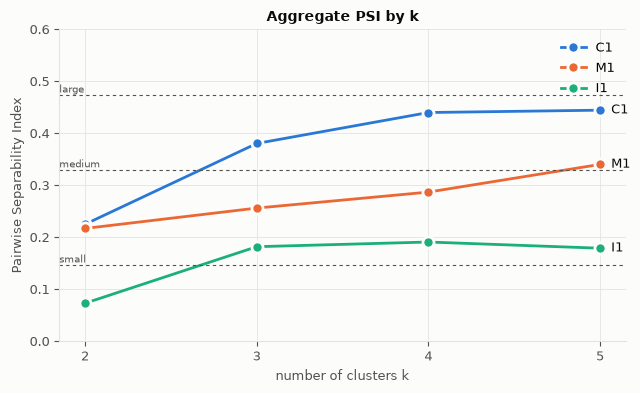

,C1 k=2,C1 k=3,C1 k=4,C1 k=5,M1 k=2,M1 k=3,M1 k=4,M1 k=5,I1 k=2,I1 k=3,I1 k=4,I1 k=5
Age,0.238 (S),0.335 (M),0.656 (L),0.571 (L),0.178 (S),0.254 (S),0.370 (M),0.371 (M),0.140 (N),0.306 (S),0.263 (S),0.228 (S)
MMSE,0.249 (S),0.666 (L),0.484 (L),0.534 (L),0.016 (N),0.141 (N),0.244 (S),0.466 (M),0.040 (N),0.169 (S),0.137 (N),0.151 (S)
nWBV,0.158 (S),0.500 (L),0.704 (L),0.681 (L),0.115 (N),0.348 (M),0.418 (M),0.502 (L),0.094 (N),0.390 (M),0.318 (S),0.273 (S)
eTIV,0.203 (S),0.173 (S),0.254 (S),0.267 (S),0.336 (M),0.324 (S),0.265 (S),0.235 (S),0.098 (N),0.191 (S),0.296 (S),0.230 (S)
Educ,0.314 (S),0.463 (M),0.459 (M),0.494 (L),0.212 (S),0.181 (S),0.230 (S),0.216 (S),0.036 (N),0.050 (N),0.043 (N),0.112 (N)
SES,0.435 (M),0.350 (M),0.370 (M),0.396 (M),0.541 (L),0.372 (M),0.328 (S),0.336 (M),0.023 (N),0.044 (N),0.060 (N),0.116 (N)
CDR,0.076 (N),0.445 (M),0.434 (M),0.459 (M),0.046 (N),0.171 (S),0.240 (S),0.401 (M),0.022 (N),0.159 (S),0.134 (N),0.098 (N)
sex,0.126 (N),0.113 (N),0.160 (S),0.154 (S),0.293 (S),0.259 (S),0.200 (S),0.194 (S),0.131 (N),0.145 (N),0.275 (S),0.222 (S)
PSI (mean),0.225 (S),0.380 (M),0.440 (M),0.444 (M),0.217 (S),0.256 (S),0.287 (S),0.340 (M),0.073 (N),0.182 (S),0.191 (S),0.179 (S)


In [4]:
psi = pd.concat([psi_column(df, results[(n, k)]["labels"], f"{n} k={k}")
                 for n in cfg.K_SELECTION_CONFIGS for k in cfg.K_CANDIDATES], axis=1)
psi.to_csv(OUT / "psi_by_k.csv")

aggregate = pd.DataFrame({n: [psi.loc["PSI (mean)", f"{n} k={k}"] for k in cfg.K_CANDIDATES]
                          for n in cfg.K_SELECTION_CONFIGS}, index=cfg.K_CANDIDATES)
fig = psi_by_k(aggregate)
fig.savefig(OUT / "psi_by_k.png", dpi=200, bbox_inches="tight")
plt.show()
format_psi_table(psi)

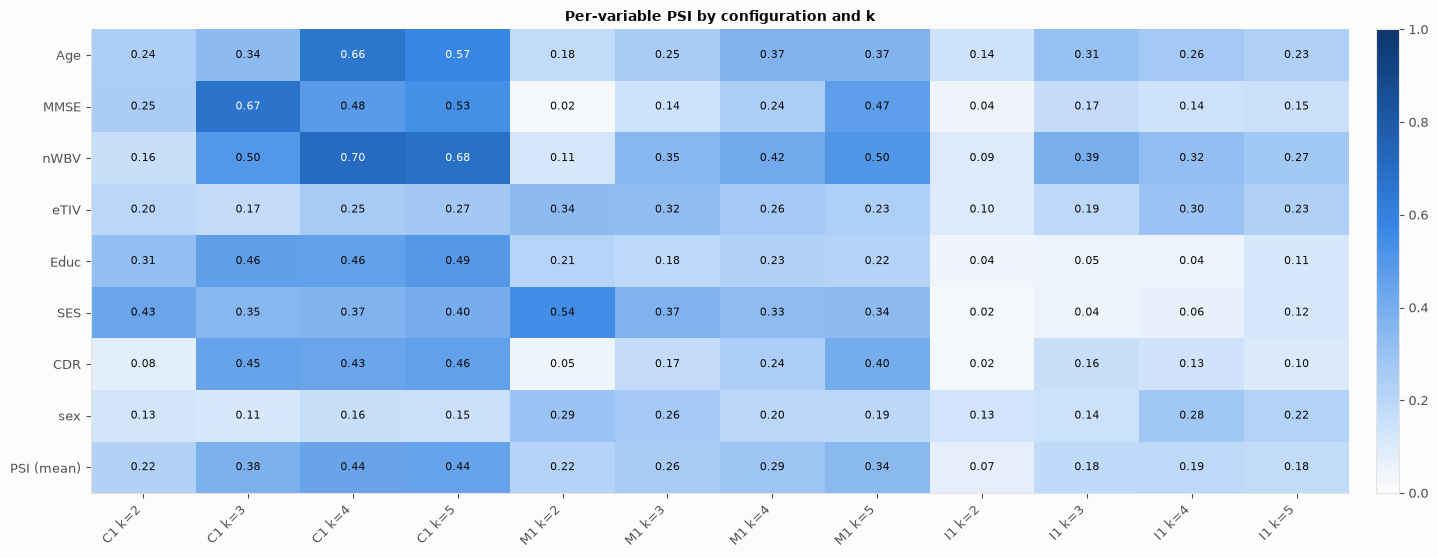

In [5]:
fig = psi_heatmap(psi, "Per-variable PSI by configuration and k")
fig.savefig(OUT / "psi_by_k_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Cluster profiles

Top row: distributions of the continuous variables (box = interquartile range, line = median,
diamond = mean). Bottom row: share of each category within each cluster.

What to look for at each k: whether the clusters differ on MMSE, CDR, nWBV and age; whether going to k + 1 adds a
new type of patient or only splits a cluster into two similar halves; and whether some clusters are very small.

### C1

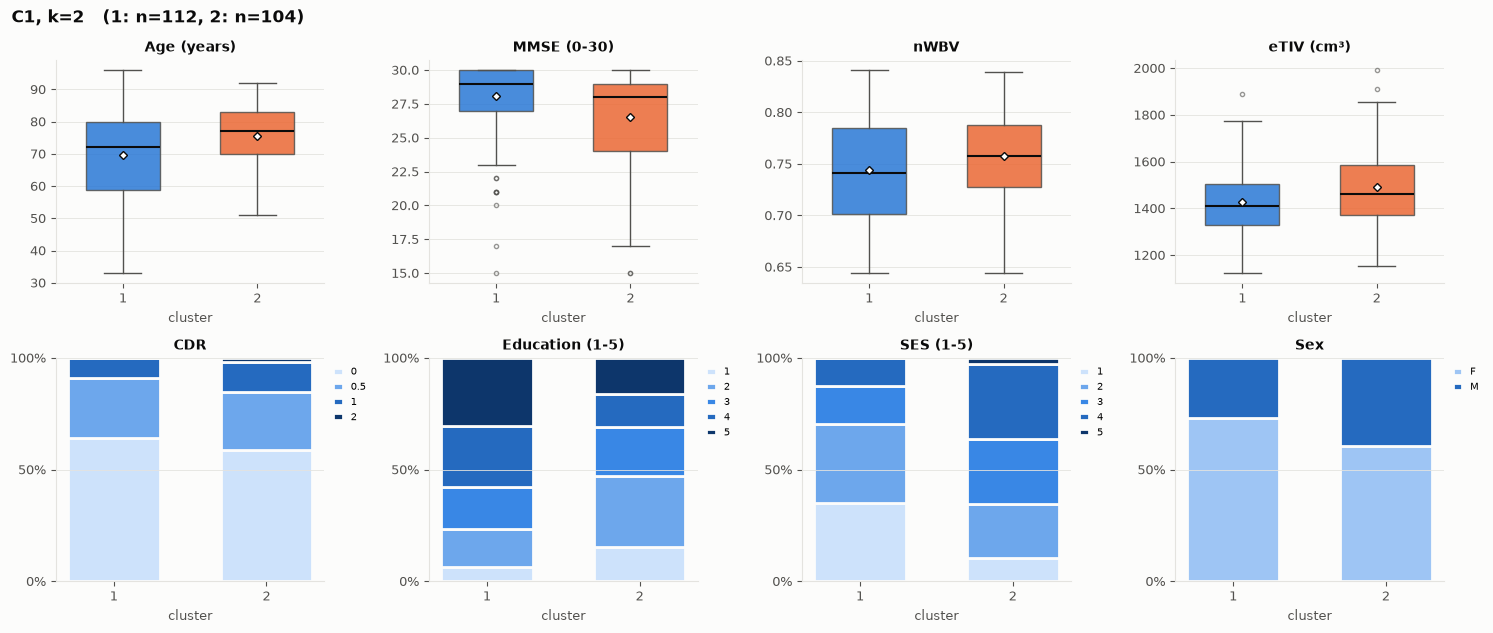

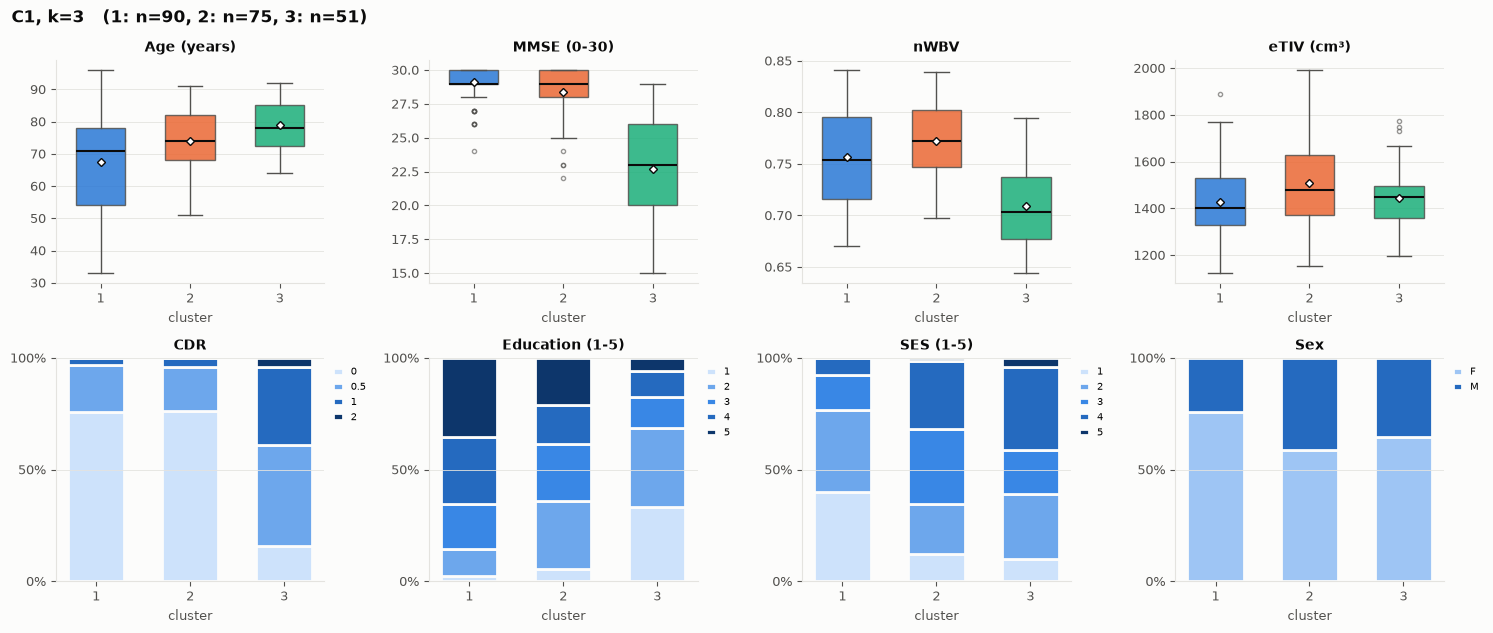

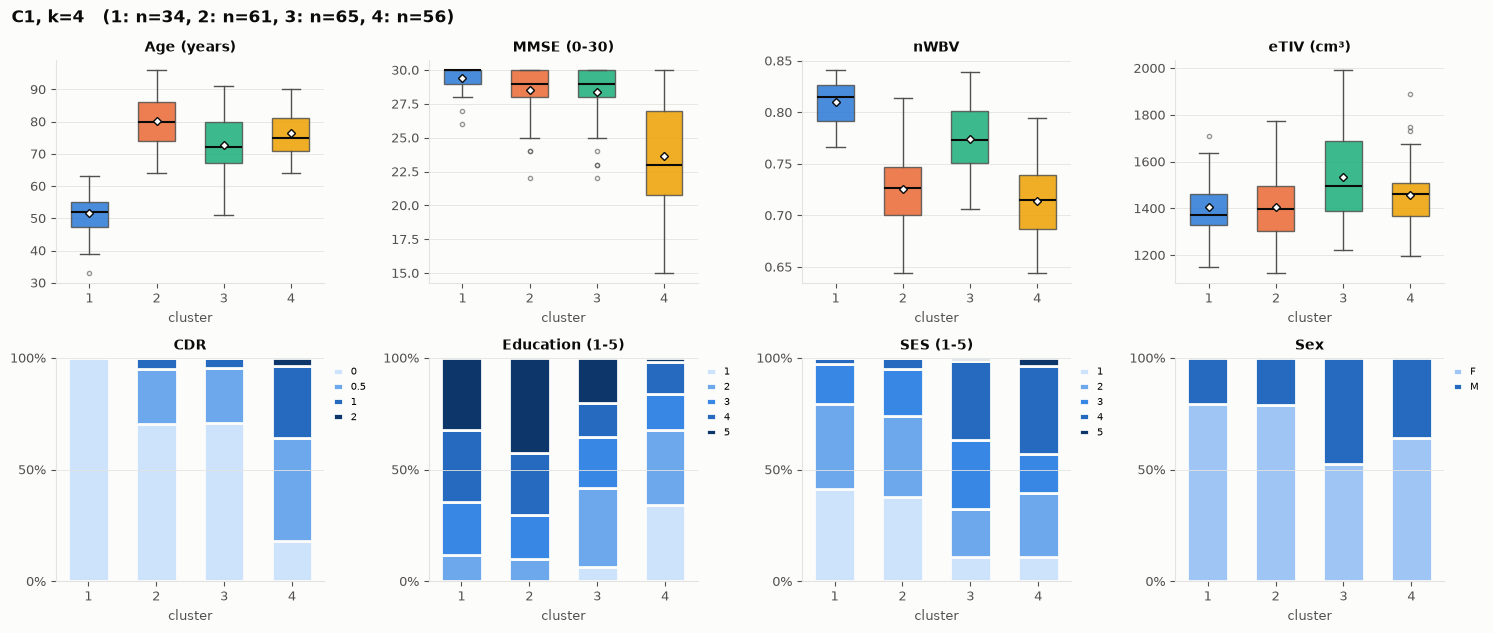

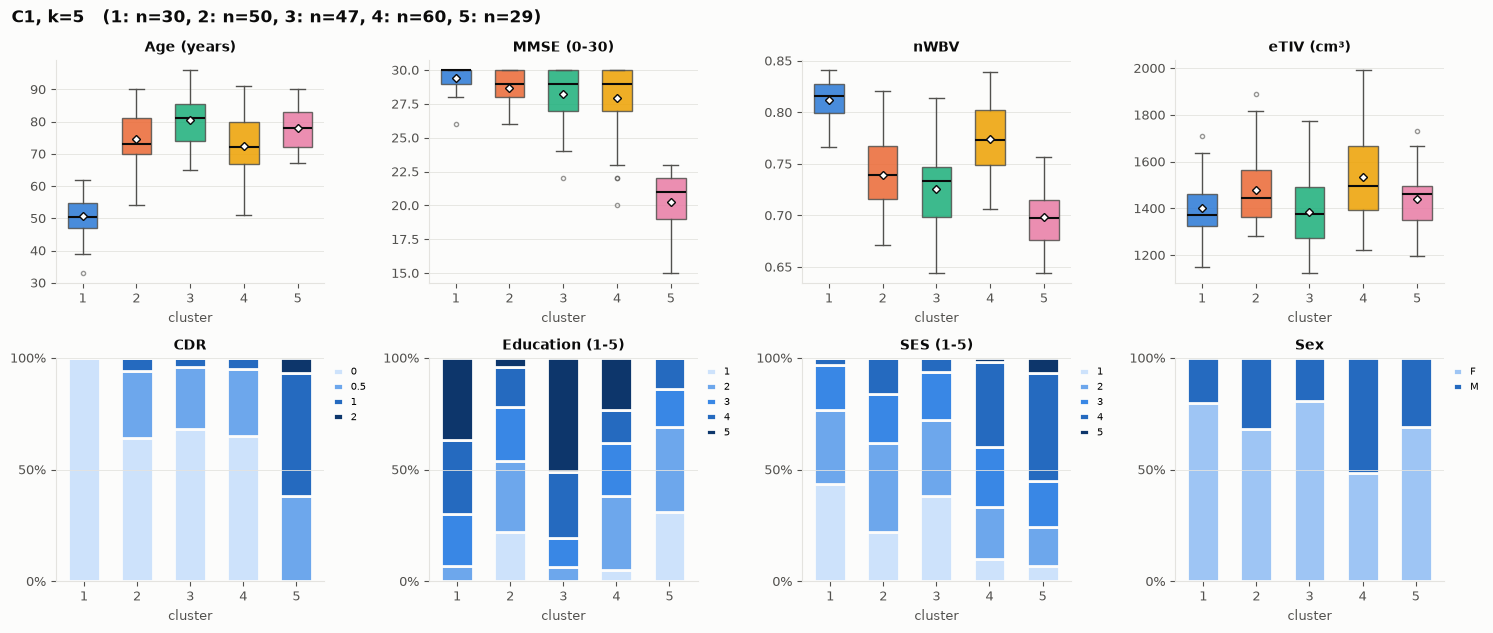

In [6]:
for k in cfg.K_CANDIDATES:
    fig = cluster_profile(df, results[("C1", k)]["labels"], f"C1, k={k}")
    fig.savefig(OUT / f"profile_C1_k{k}.png", dpi=200, bbox_inches="tight")
    plt.show()

### M1

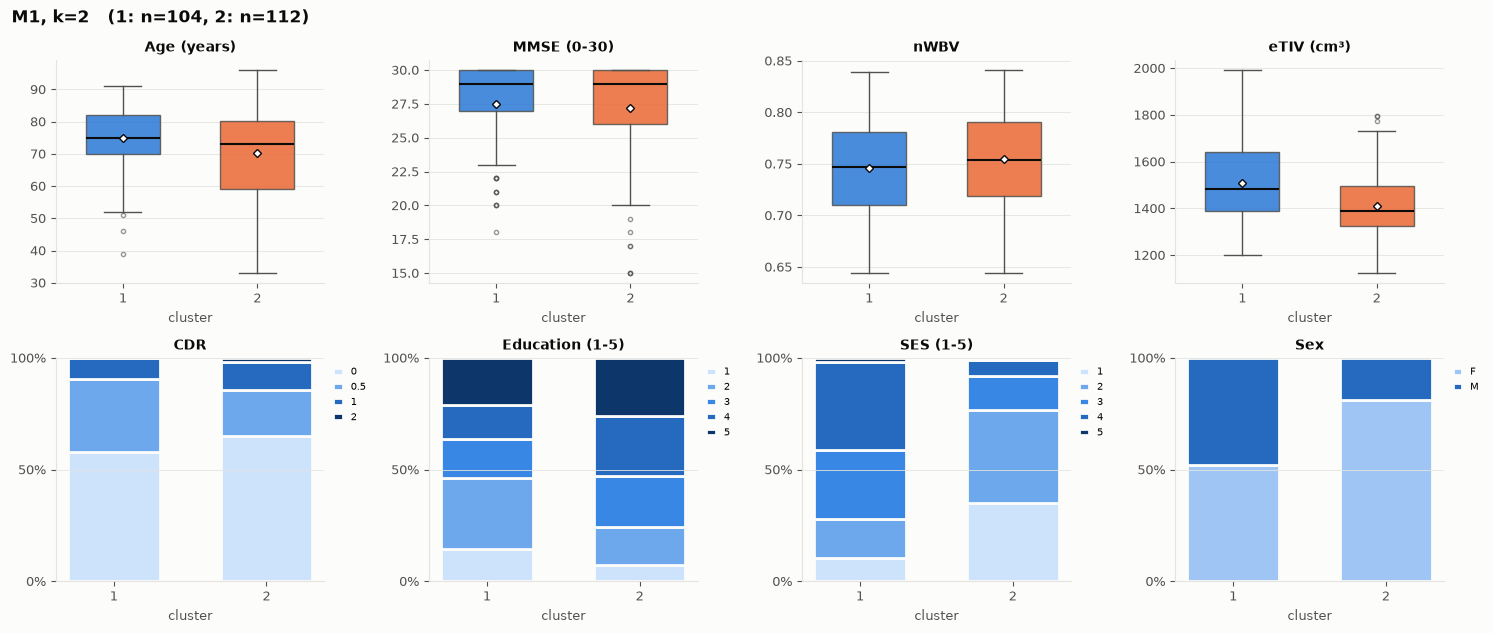

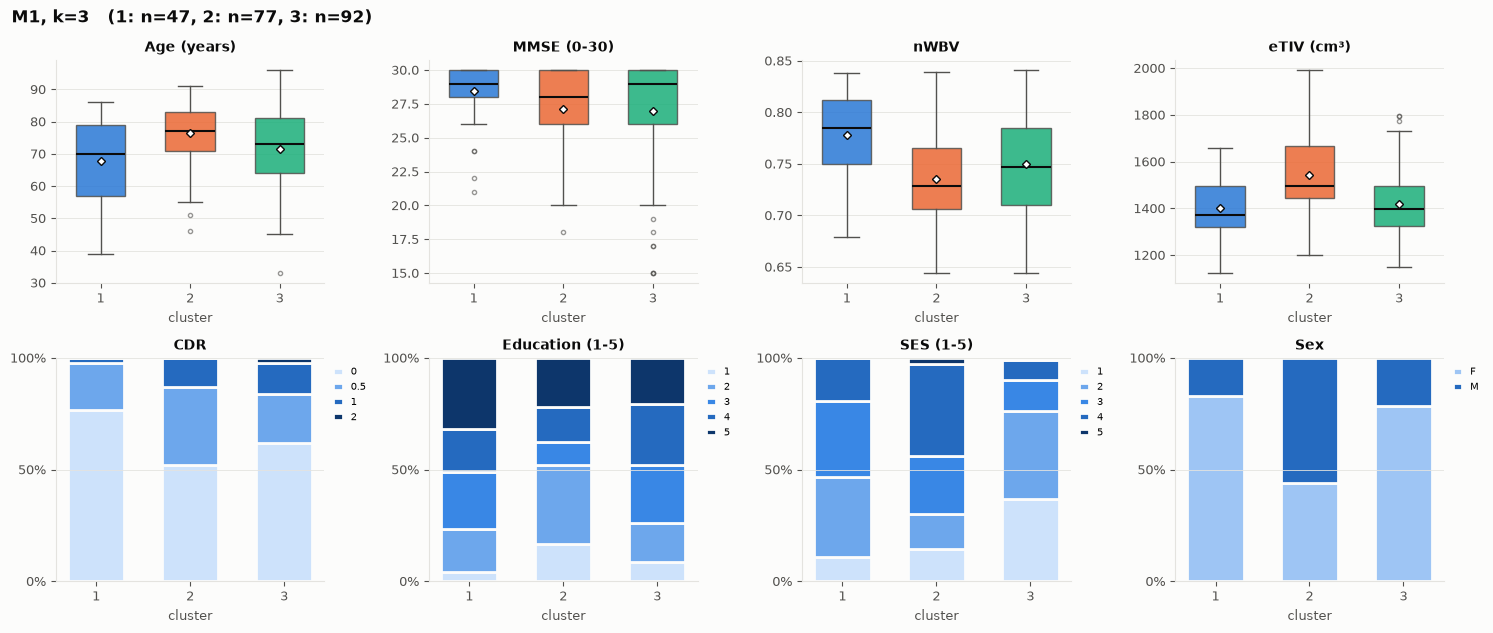

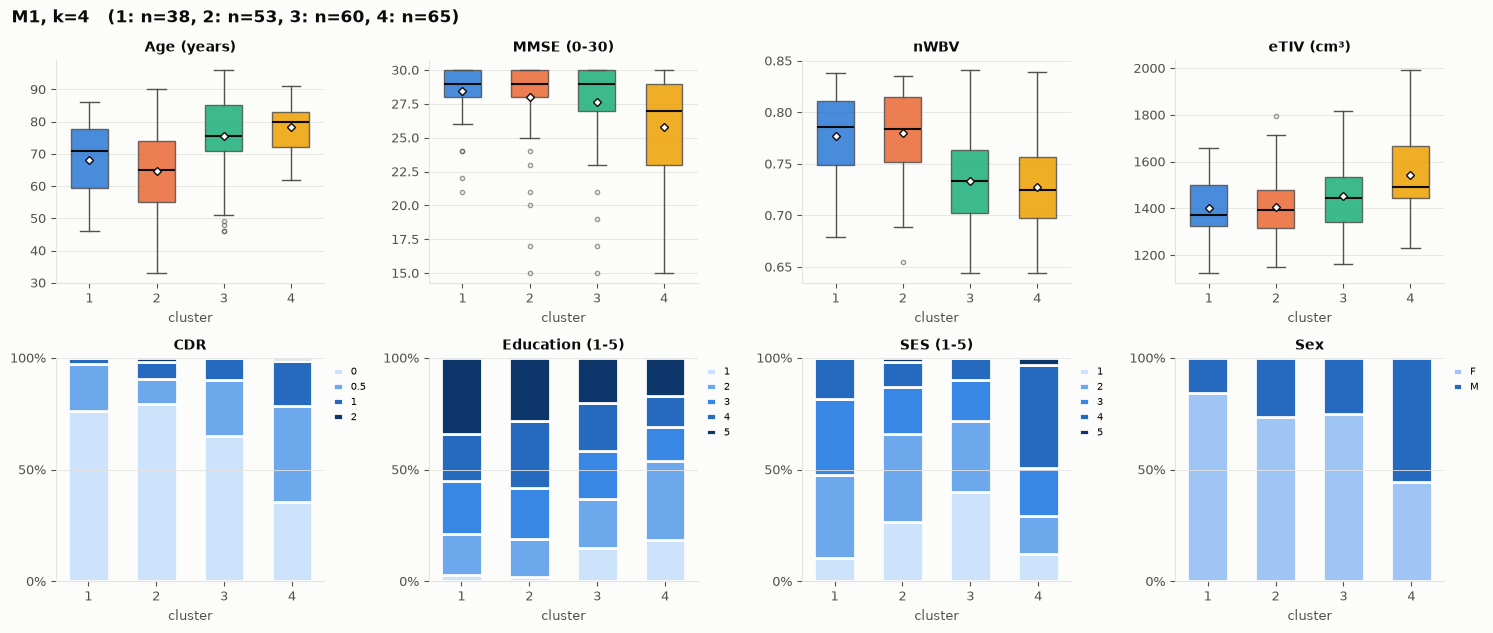

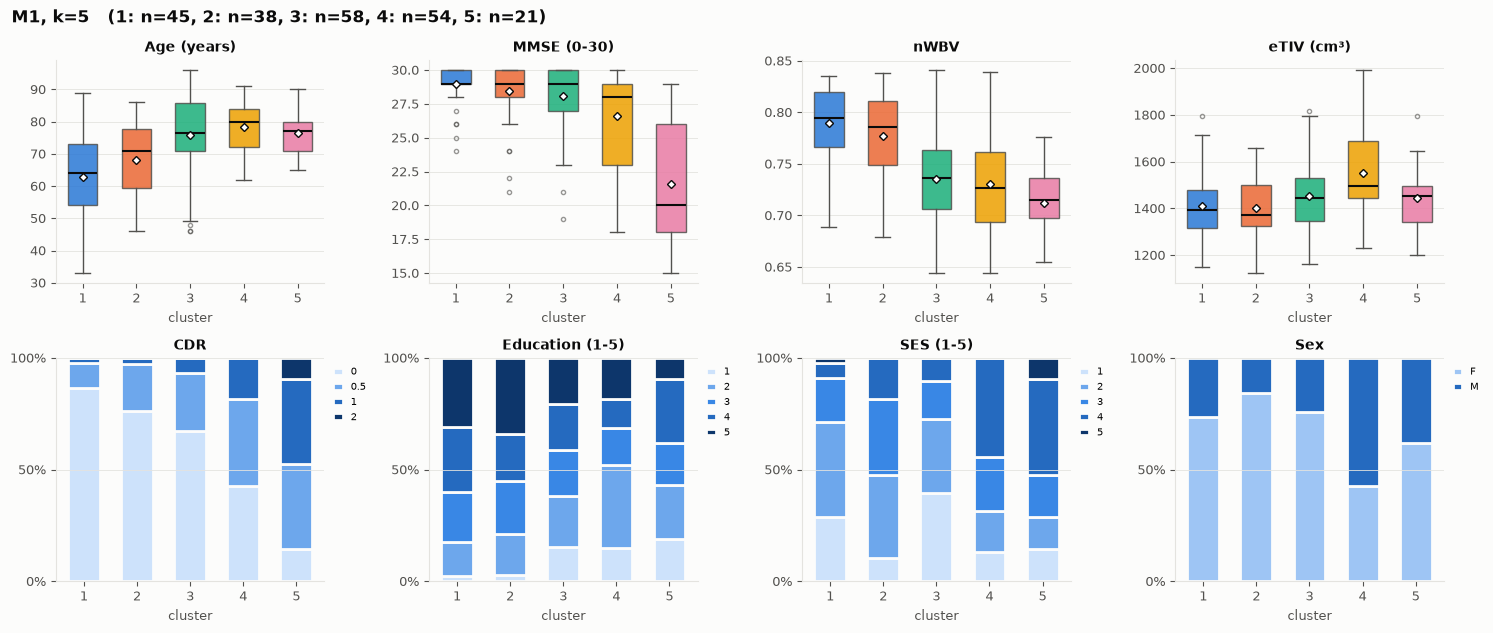

In [7]:
for k in cfg.K_CANDIDATES:
    fig = cluster_profile(df, results[("M1", k)]["labels"], f"M1, k={k}")
    fig.savefig(OUT / f"profile_M1_k{k}.png", dpi=200, bbox_inches="tight")
    plt.show()

### I1

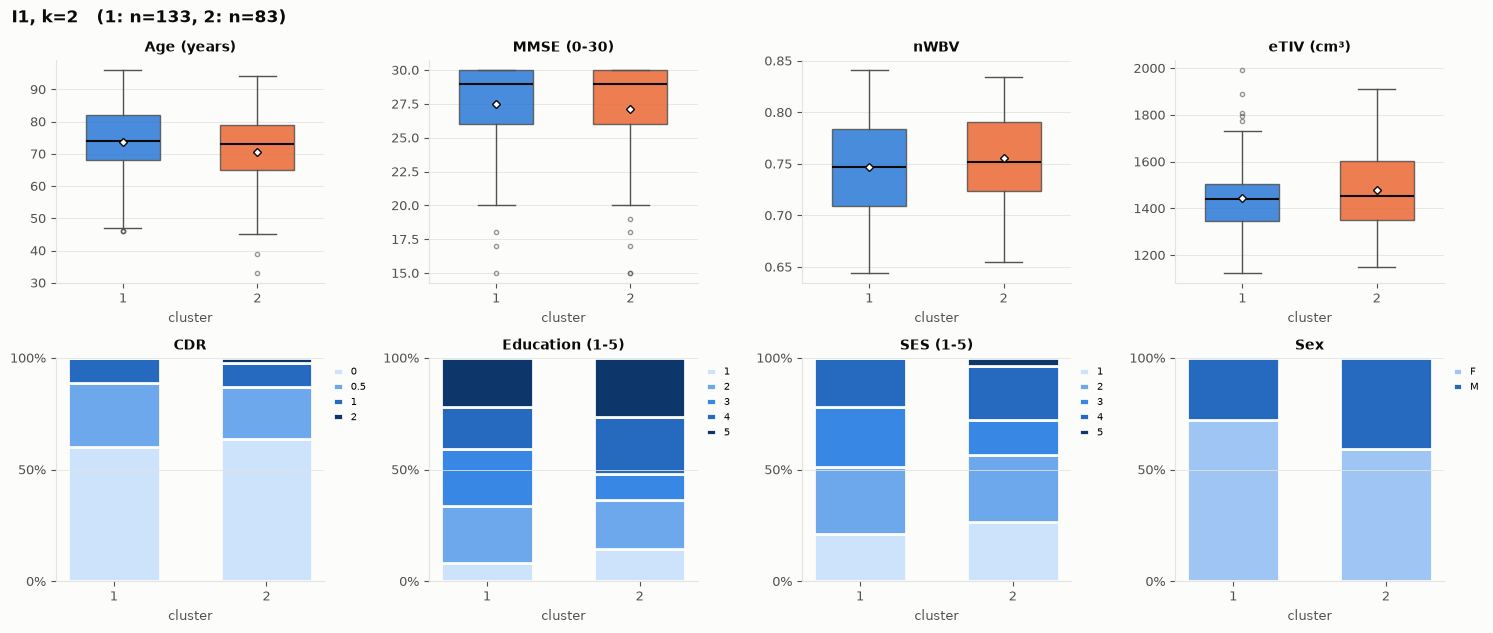

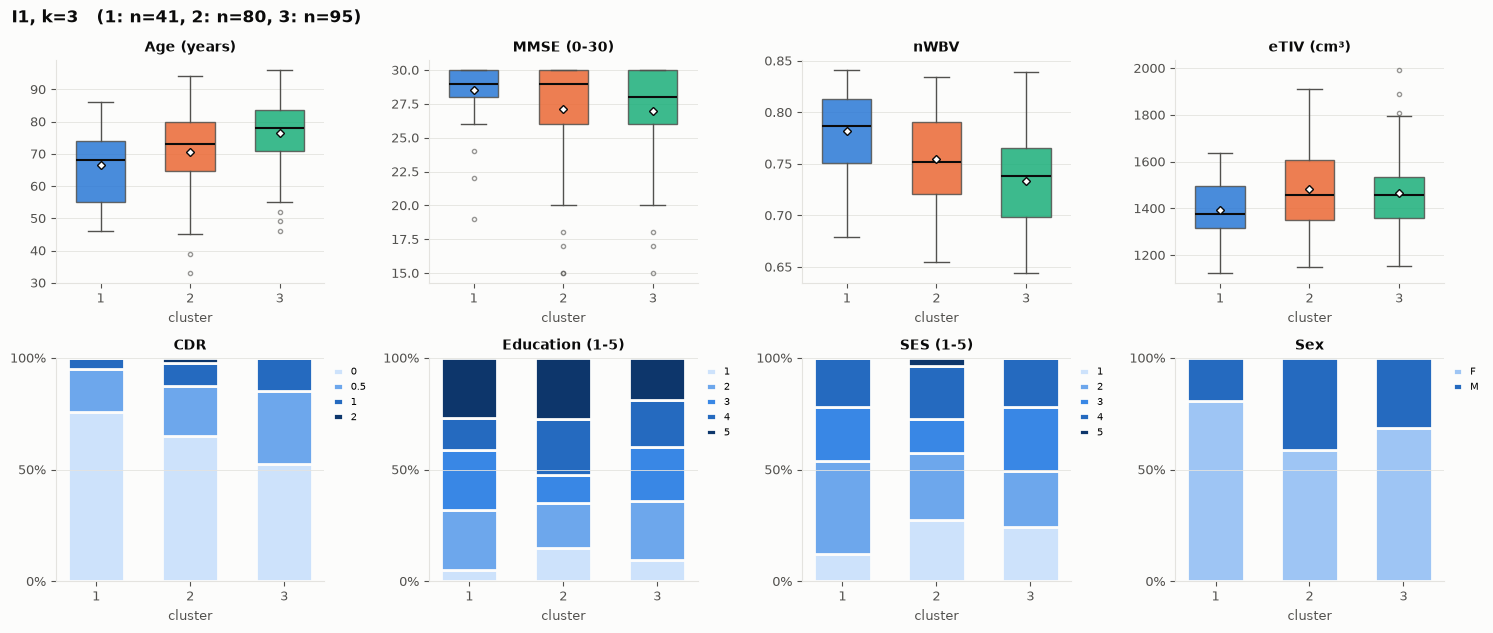

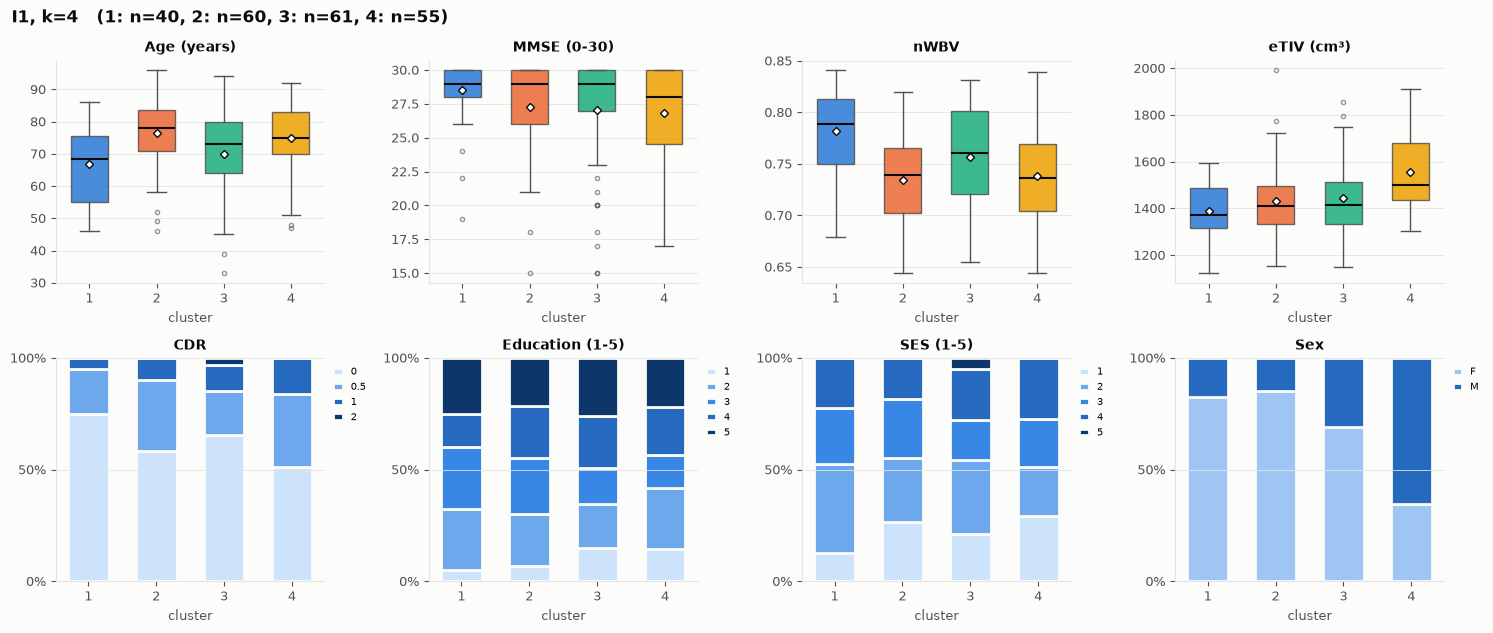

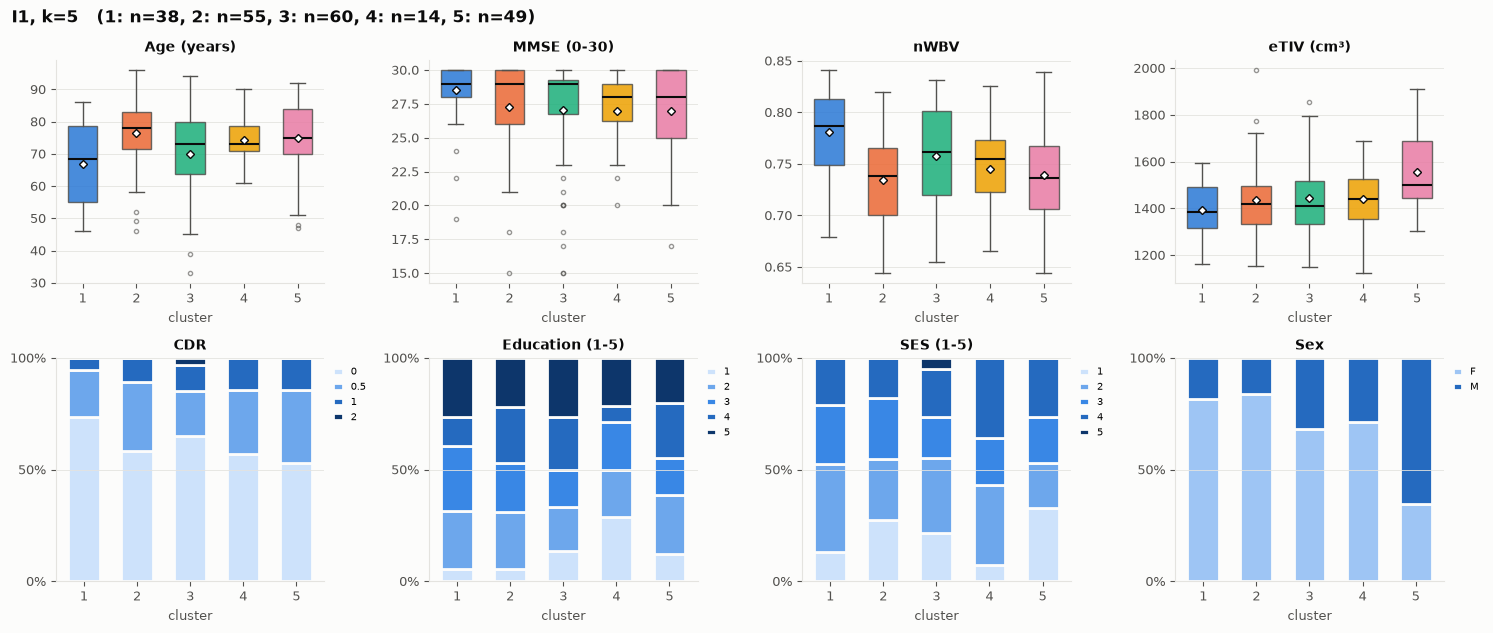

In [8]:
for k in cfg.K_CANDIDATES:
    fig = cluster_profile(df, results[("I1", k)]["labels"], f"I1, k={k}")
    fig.savefig(OUT / f"profile_I1_k{k}.png", dpi=200, bbox_inches="tight")
    plt.show()

## 5. Medoid patients

The medoid is the real patient that represents each cluster.

In [9]:
for name in cfg.K_SELECTION_CONFIGS:
    for k in cfg.K_CANDIDATES:
        r = results[(name, k)]
        print(f"\n{name}, k={k}")
        display(medoid_table(df, r["labels"], r["medoids"]))


C1, k=2


,cluster,n,medoid,sex,Age,MMSE,CDR,nWBV,eTIV,Educ,SES
0,1,112,OAS1_0292,F,64,30.0,0.0,0.766,1415,4.0,2.0
1,2,104,OAS1_0139,F,72,28.0,0.0,0.779,1512,3.0,3.0



C1, k=3


,cluster,n,medoid,sex,Age,MMSE,CDR,nWBV,eTIV,Educ,SES
0,1,90,OAS1_0292,F,64,30.0,0.0,0.766,1415,4.0,2.0
1,2,75,OAS1_0139,F,72,28.0,0.0,0.779,1512,3.0,3.0
2,3,51,OAS1_0268,M,78,23.0,1.0,0.715,1491,2.0,3.0



C1, k=4


,cluster,n,medoid,sex,Age,MMSE,CDR,nWBV,eTIV,Educ,SES
0,1,34,OAS1_0044,F,47,30.0,0.0,0.829,1346,4.0,2.0
1,2,61,OAS1_0244,F,80,29.0,0.0,0.737,1341,4.0,2.0
2,3,65,OAS1_0139,F,72,28.0,0.0,0.779,1512,3.0,3.0
3,4,56,OAS1_0268,M,78,23.0,1.0,0.715,1491,2.0,3.0


... (14 outputs left out)


I1, k=4


,cluster,n,medoid,sex,Age,MMSE,CDR,nWBV,eTIV,Educ,SES
0,1,40,OAS1_0109,F,61,30.0,0.0,0.813,1313,4.0,3.0
1,2,60,OAS1_0217,F,78,27.0,0.5,0.692,1393,4.0,3.0
2,3,61,OAS1_0308,F,78,15.0,2.0,0.703,1401,3.0,3.0
3,4,55,OAS1_0016,M,82,27.0,0.5,0.739,1477,2.0,4.0



I1, k=5


,cluster,n,medoid,sex,Age,MMSE,CDR,nWBV,eTIV,Educ,SES
0,1,38,OAS1_0109,F,61,30.0,0.0,0.813,1313,4.0,3.0
1,2,55,OAS1_0217,F,78,27.0,0.5,0.692,1393,4.0,3.0
2,3,60,OAS1_0308,F,78,15.0,2.0,0.703,1401,3.0,3.0
3,4,14,OAS1_0453,F,70,29.0,0.5,0.748,1295,1.0,4.0
4,5,49,OAS1_0016,M,82,27.0,0.5,0.739,1477,2.0,4.0


## 6. Elbow curve and silhouette

The elbow curve decreases smoothly, without a clear bend, and the silhouettes are low (at most about 0.16 for
C1 and about 0.02 for M1 and I1). The patients form a continuum rather than separate groups, so neither of
these can choose k on its own. Each curve uses its configuration's own distance, so only the shapes can be
compared between configurations.

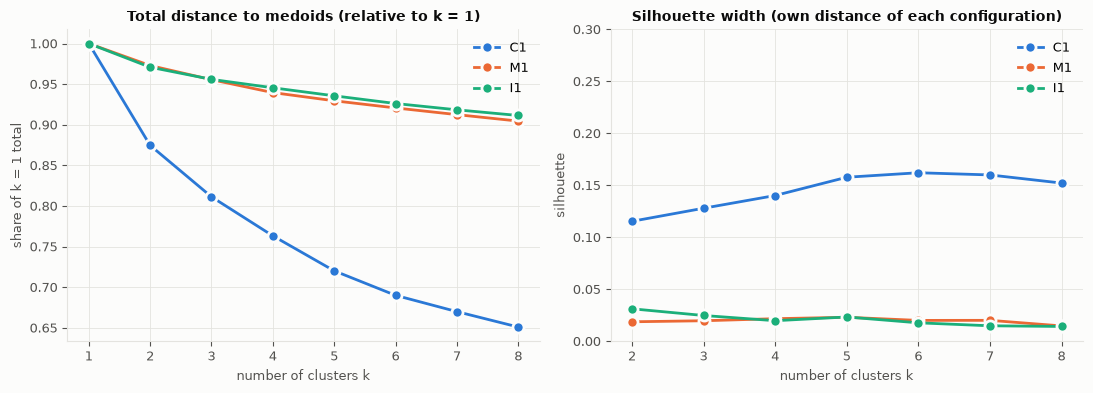

% decrease in total distance when adding one cluster:


,C1,M1,I1
1->2,12.5,2.7,2.9
2->3,7.2,1.8,1.5
3->4,5.9,1.7,1.1
4->5,5.6,1.1,1.0
5->6,4.2,0.9,1.0
6->7,2.9,0.9,0.8
7->8,2.8,0.9,0.8


In [10]:
from sklearn.metrics import silhouette_score

ks = range(1, 9)
cost, sil = {}, {}
for name in cfg.K_SELECTION_CONFIGS:
    D = results[(name, 2)]["D"]
    cost[name], sil[name] = [D.sum(axis=1).min()], []
    for k in ks[1:]:
        r = results.get((name, k)) or fit_configuration(name, k, df)
        cost[name].append(D[np.arange(len(D)), r["medoids"][np.argmin(D[:, r["medoids"]], axis=1)]].sum())
        sil[name].append(silhouette_score(D, r["labels"], metric="precomputed"))
cost = pd.DataFrame(cost, index=list(ks))
sil = pd.DataFrame(sil, index=list(ks)[1:])

fig = elbow_and_silhouette(cost, sil)
fig.savefig(OUT / "elbow_silhouette.png", dpi=200, bbox_inches="tight")
plt.show()
print("% decrease in total distance when adding one cluster:")
(-cost.pct_change() * 100).iloc[1:].round(1).rename(index=lambda k: f"{k-1}->{k}")

## 7. Decision: k = 4

Reasoning for the clinical reference configuration C1 (medians per cluster in brackets):

| k | Limitation | What the clusters show | Decision |
|---|---|---|---|
| 2 | impaired patients not separated | two mixed groups (36% and 41% with CDR > 0); MMSE PSI 0.25, CDR PSI 0.08 | rejected |
| 3 | different healthy profiles merged | one impaired cluster (MMSE 23, 84% CDR > 0) and two healthy ones, one of them with ages from 33 to 96 | rejected |
| **4** | – | young healthy (52 y, highest nWBV, no CDR > 0) · older healthy with atrophy (80 y, low nWBV, highly educated) · healthy, larger head, more men, lower education (72 y) · cognitively impaired (MMSE 23, 82% CDR > 0, low nWBV) | **selected**: four distinct profiles; PSI 0.44, with large separation on nWBV (0.70), Age (0.66) and MMSE (0.48) |
| 5 | redundant split | splits the older healthy patients by education (median 2 vs 5) and shrinks the impaired cluster to 29 patients; PSI unchanged (0.444 vs 0.440) | rejected |

M1 and I1 agree with this: at k = 4 M1 also has an older, more impaired cluster (65% CDR > 0), and I1 is weak at
every k (PSI ≤ 0.19), with its highest value at k = 4.

`K = 4` is set in `src/config.ipynb`.